In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\dataset_kriminal_smote_gabungan2.csv')

In [3]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1


In [4]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 80721


In [5]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 14


In [6]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita           0
isi_berita             0
text_clean             0
label_kriminal         0
label_krim_gabungan    0
dtype: int64


In [7]:
df = df.drop_duplicates().reset_index(drop=True)

In [8]:
categories = {
    'Pembunuhan': [
        'pembunuhan', 'tewas','dibunuh', 'membunuh','mutilasi', 'dimutilasi','dihabisi', 'menghabisi nyawa','eksekusi', 'dieksekusi','pembantaian', 'dibantai','pembunuh berantai', 'serial killer', 'pembunuh bayaran',
        'mati ditikam', 'ditembak mati', 'diracun','jasad', 'mayat', 'jenazah','nyawa melayang', 'tewas mengenaskan','jasad kaku', 'tubuh tak bernyawa','mayat tanpa identitas','jasad terbakar', 'jasad terbungkus',
        'mayat dalam karung', 'jasad bayi', 'jasad dicor','tewas bersimbah darah', 'meregang nyawa','hilang nyawa', 'tubuh terpotong','mutilasi tubuh', 'tewas tergantung','mayat membusuk', 'kerangka manusia',
        'kerangka tulang', 'jasad tinggal tulang','dikubur massal', 'pembunuhan sadis','pembunuhan','menghabisi korbannya','tak hembusan napas','kehilangan nyawanya',
        'ditikam hingga tewas', 'menikam hingga tewas', 'dibacok hingga tewas', 'membacok hingga tewas', 'dicekik hingga tewas', 'mencekik hingga tewas', 'diracun hingga tewas', 'meracuni hingga tewas', 'dijerat hingga tewas', 'dibekap hingga tewas', 
        'dianiaya hingga tewas', 'dipukuli hingga tewas', 'dihantam hingga tewas', 'ditembak hingga tewas', 'dibenamkan hingga tewas', 'tewas diracun', 'tewas digorok', 'tewas dimutilasi', 'tewas ditembak', 'pembunuhan berencana', 'rekonstruksi pembunuhan', 'menghilangkan jasad', 'membuang jasad', 'menyembunyikan jasad', 'mayat dicor semen', 
        'jasad dicor semen','hingga tewas','otak pelaku pembunuhan', 'skenario pembunuhan', 'rekayasa pembunuhan','berencana menghabisi', 'rencana pembunuhan', 'perencanaan pembunuhan','menghabisi satu keluarga', 'pembantaian keluarga', 
        'pasal 340 kuhp', 'pasal 338 kuhp', 'dijerat pasal pembunuhan','didakwa pembunuhan', 'terdakwa pembunuhan', 'terpidana pembunuhan', 'sidang kasus pembunuhan', 'potongan tubuh', 'jasad terbungkus seprai', 
        'mayat terbungkus plastik', 'jasad terbungkus plastik', 'dikubur dalam rumah', 'dikubur di kamar', 'dikubur di dalam', 'menyembunyikan mayat', 'membuang mayat',
    
    ],
    'Kejahatan Seksual dan Asusila': [
        'perkosa', 'memperkosa', 'diperkosa', 'pemerkosaan','cabul', 'mencabuli', 'dicabuli', 'pencabulan','pelecehan seksual', 'kekerasan seksual','pemaksaan seksual','sodomi', 'disodomi', 'menyodomi','perdagangan orang','tppo','seks','pesta seks','pesta gay','puluhan pria bugil','bugil','tindak asusila', 
        'rudapaksa', 'dirudapaksa','setubuhi', 'disetubuhi', 'menyetubuhi', 'persetubuhan','gagahi', 'digagahi', 'menggagahi','begal payudara', 'begal bokong','dipaksa melayani','melahirkan di rumah kosong', 'hamil di luar nikah', 'melahirkan tanpa suami','pembuangan bayi', 'bayi dibuang',
        'tindakan asusila', 'tindakan tidak senonoh','pemerasaan seksual','prostitusi', 'open bo','mucikari', 'muncikari', 'germo','budak seks', 'seks komersial', 'pijat plus plus','eksploitasi seksual','menjalankan bisnis prostitusi','prostitusi berkedok panti','pria hidung belang','praktik prostitusi','aktivitas prostitusi',
        'predator anak', 'pedofilia', 'ekshibisionis','catcalling', 'stalking seksual','pelecehan non fisik', 'pelecehan fisik','kerusakan alat vital','tpks', 'uu tpks','oknum guru cabul','korban percobaan perkosaan','penyekapan','penculikan','penganiayaan','perampasan kemerdekaan','perdagangan orang','perdagangan anak','eksploitasi seksual',
        'kekerasan seksual','kejahatan asusila','pelanggaran kesusilaan','penyanderaan','penculikan anak','perdagangan bayi','eksploitasi anak','prostitusi paksa','pelecehan seksual','pemaksaan seksual','disekap','perlakuan tidak senonoh','aksi pemerkosaan','menghamili adik kandungnya','memperkosa korban','memperkosa','diduga pelecehan verbal','pelecehan verbal',
        'pencabulan anak bawah', 'pencabulan anak kandung', 'ayah cabuli anak', 'pencabulan sesama jenis', 'pemerkosaan bergilir', 'rudapaksa anak', 'tindakan rudapaksa', 'pencabulan bermodus', 'pencabulan berkedok', 'pencabulan santri', 'pencabulan siswa', 'pencabulan siswi', 'oknum dosen cabul', 'oknum ustadz cabul', 'pelecehan dalam angkot', 'pelecehan di kereta', 'pelecehan di angkutan', 'meraba tubuh korban', 'memegang tubuh korban', 'memaksa bersetubuh', 
        'pesta seks bebas', 'prostitusi terselubung', 'germo prostitusi', 'mucikari prostitusi', 'lokalisasi prostitusi', 'perdagangan anak perempuan', 'eksploitasi seksual anak', 'sindikasi tppo', 'pelecehan seksual massal', 'pelecehan seksual berulang', 'visum korban pelecehan',  'kerusakan alat kelamin','dipaksa melayani nafsu', 'melayani nafsu bejad', 'melayani nafsu pelaku', 'menodai korban', 'menodai anak kandungnya', 'disekap di kamar', 'disekap di hotel', 'disekap di kos', 'korban perdagangan orang', 'dipekerjakan sebagai psk', 'menjual korban ke', 'tarif sekali kencan', 'praktik prostitusi terselubung','penggerebekan wisma prostitusi', 'penggerebekan panti pijat', 'panti pijat plus', 'bisnis esek esek',
        'meniduri', 'ditiduri', 'menggilir', 'digilir', 'inses', 'sperma', 'kondom', 'pedofil',  'nyosor', 'meraba', 'diraba', 'meremas', 'diremas','rudapaksa', 'dirudapaksa', 'cabul', 'pencabulan', 'mencabuli', 'dicabuli', 'sodomi', 'disodomi', 
        'menyodomi', 'menyetubuhi', 'disetubuhi', 'persetubuhan', 'menggagahi', 'digagahi', 'menodai', 'dinodai', 'disekap', 'penyekapan', 'penculikan',
        'pencabulan anak tiri', 'pencabulan balita', 'bujuk rayu persetubuhan', 'persetubuhan anak bawah', 'persetubuhan anak kandung', 'perselingkuhan',
        'menyetubuhi anak tiri', 'disetubuhi ayah tiri', 'memaksa melakukan persetubuhan', 'pemerkosaan sedarah', 'melakukan perbuatan cabul', 
        'kasus kekerasan seksual', 'pemberatan kasus seksual', 'tindak pidana pencabulan', 'pencabulan di bawah', 'pelaku pencabulan anak', 
        'berbuat cabul', 'mencabuli anak tiri', 'dicabuli ayah tiri', 'korban kekerasan seksual', 'melakukan asusila terhadap', 'dihamili pria','korban hamil','pemerkosa anak keterbelakangan','pelaku pemerkosaan tetangga','pemerkosa','pemerkosa 13 santriwati','mengeksploitasi pacarnya','menjual korban','mengandung usia kehamilannya','dipaksa pacarnya melayani',
        'germo lokalisasi', 'wisma lokalisasi', 'bisnis prostitusi liar', 'prostitusi jalanan', 'pekerja seks komersial','pemerkosaan remaja','tersangka pemerkosaan remaja',
    ],
    'Narkotika': [
        'sabu', 'ganja', 'ekstasi','narkoba', 'narkotika','pil koplo', 'sinte','tramadol', 'eximer', 'hexymer','tembakau sintetis', 'tembakau gorila','putauw', 'heroin', 'kokain','shabu-shabu',
        'alat hisap', 'bong', 'nyabu','psikotropika', 'obat daftar g','trihexyphenidyl', 'alprazolam','riklona', 'diazepam', 'benzo', 'dumolid','methamphetamine', 'mdma','pabrik sabu', 'home industri sabu',
        'clandestine lab','prekursor narkotika','narkoba cair', 'narkoba jenis baru','sabu dalam kemasan teh','sabu antar provinsi','pasal 112 uu narkotika','pasal 114 uu narkotika','swallow','bandar sabu terbesar',
        'pengedar narkoba', 'bandar narkoba', 'kurir narkoba', 'gembong narkoba', 'sindikat narkoba', 'penyelundupan narkoba', 'peredaran narkoba', 'transaksi narkoba', 'pesta narkoba', 'jaringan narkoba', 'sabu cair', 'ganja kering', 'pohon ganja', 'ladang ganja', 'paket sabu', 
        'sabu klip', 'klip sabu', 'pipet kaca', 'kaca pipet', 'timbangan digital', 'penggerebekan narkoba', 'satresnarkoba', 'sat narkoba', 'ditresnarkoba', 'bnnk', 'bnnp', 'positif narkoba', 'positif amfetamin', 'pecandu narkoba', 
        'rehabilitasi narkoba', 'sakau', 'overdosis', 'carisoprodol', 'somadril', 'peredaran pil ekstasi','pemberantasan badan narkotika','pengiriman narkoba','pengiriman narkoba ekstasi','peredaran pil ekstasi','pengiriman pil ekstasi',
        'koplo', 'amfetamin', 'barbiturat', 'galian ganja', 'bunderan sabu','gembong narkotika','pengedar sabu', 'bandar sabu', 'kurir sabu', 'transaksi sabu', 'pemakai sabu', 'penyelundupan sabu', 'pesta narkoba','pesta sabu',
    ],
    'Penipuan & Ekonomi': [
        'penipuan', 'menilap','tipu','investasi bodong','meraup untung','meraup', 'investasi ilegal','korupsi', 'tindak pidana korupsi','suap', 'suap menyuap', 'gratifikasi','penggelapan','pencucian uang', 'money laundering', 'tppu','pencucian uang kripto',
        'mafia tanah','skema ponzi','upal', 'uang palsu','robot trading', 'binomo','arisan bodong', 'umrah bodong','pungli', 'pungutan liar','kerugian negara', 'kerugian keuangan negara','penggandaan uang','pemerasan','pengedar uang palsu','menyita uang palsu','mencetak uang','ditangkap kpk',
        'pinjol ilegal', 'joki pinjol', 'galbay','debt collector','kredit fiktif','pemalsuan dokumen','rekayasa proyek','trading plan palsu','loker fiktif','penipuan kerja luar negeri','undian palsu', 'tebus hadiah','penimbunan solar','penimbunan','promosi jabatan',
        'struk palsu', 'bukti transfer palsu', 'qris palsu','penggelapan','penggelapan dana','pencucian uang',' menilap uang nasabah','memalsukan tanda tangan','menilap','korupsi dana corporate','korupsi dana','dugaan korupsi','dugaan korupsi dana','tersangka korupsi', 'terdakwa korupsi', 'kasus korupsi', 'terpidana korupsi', 'sidang tipikor', 'melarikan uang', 'penggelapan dalam jabatan', 'menggelapkan dana', 'menggelapkan uang', 'menggelapkan aset', 
        'pemalsuan surat', 'memalsukan surat', 'surat palsu', 'sertifikat palsu', 'bpkb palsu', 'stnk palsu', 'ijazah palsu', 'ktp palsu','suap oknum', 'menerima suap', 'pemberi suap', 'menyuap oknum', 'aliran dana korupsi', 'tersangka penipuan', 'pelaku penipuan', 'modus penipuan', 'korban penipuan', 
        'sindikate penipuan', 'kedok investasi', 'menipu ratusan', 'menipu puluhan', 'membawa kabur uang', 'melarikan uang', 'penggelapan dalam jabatan', 'menggelapkan dana', 'menggelapkan uang', 'menggelapkan aset', 'penyelundupan ekspor emas','membawa kabur uang','peredaran uang palsu','menukarkan uang palsu','menukarkan uang','pemerasan oknum','pemerasan','mengedarkan uang palsu',
        'penyelundup bahan bakar','penimbunan','gudang penimbunan','pasal 54 uu nomor 22 2001','dugaan penyelewengan dana','penyelewengan dana petinggi','penyelewengan','mengantarkan uang palsu','perkara mafia tanah','modus menimbun persawahan','mafia tanah',
    ],
    'Pencurian & Perampokan': [
        'pencurian', 'maling','pencuri', 'perampokan', 'perampok','curat', 'curas', 'curanmor', 'jambret', 'copet','bobol rumah', 'bobol toko', 'bobol gudang', 'bobol brankas','merampas','rampas','dirampas', 'ganjal atm', 'tukar kartu atm','gasak','barang tadahan', 'penadah','penjambretan','pencurian dengan pemberatan','bajing loncat','pencurian listrik','pencurian kabel','pencurian minyak','ilegal tapping','spesialis rumah kosong','pembegalan','dibegal','begal', 'curis', 'pencurian dengan kekerasan', 'pencurian kendaraan bermotor',  
        'curi ternak', 'pencurian hewan', 'maling','perampasan', 'penjarahan', 'dijarah', 'menggasak', 'memboyong','motor raib', 'rumah disatroni', 'satroni', 'pencoleng','pencurian kotak amal', 'pencurian spesialis', 'pencurian modus','dibegal','membegal','mencuri sabun','teriak maling maling','mengaku mencuri sabun','dicopet',
        'merampas ponsel','merampas','merampas harta korbannya','merampas harta','uang hasil curian','curian','pencopet beraksi','pencopet','ditangkap enam pencopet','pencopet diamankan','dicopet',
        'tersangka pencurian', 'pelaku pencurian', 'kasus pencurian', 'modus pencurian', 'komplotan pencurian', 'menggelapkan 13 mobil','menggelapkan','penggelapan','komplotan pembobol mesin','mengincar mesin atm','menjebol mesin atm',
        'sindikat pencurian', 'komplotan maling', 'aksi maling', 'maling motor', 'maling hp', 'kawanan pencuri','kawanan pencuri membobol','raib','dibobol pencuri','beraksi pencuri mencabut','aksi pencuri terekam','pelaku curanmor','menimbun',
        'komplotan perampok', 'aksi perampokan', 'tersangka perampokan', 'kawanan perampok', 'perampok bersenjata', 'membawa lari gelang',
        'pelaku curanmor', 'komplotan curanmor', 'sindikat curanmor', 'pelaku jambret', 'komplotan jambret', 'penyelundupan amunisi senjata',
        'aksi jambret', 'pelaku copet', 'komplotan copet', 'aksi copet', 'penadah barang', 'membawa kabur motor', 'membawa kabur mobil', 'menggasak uang', 'menggasak perhiasan', 'barang curian', 
        'toko dibobol', 'rumah dibobol', 'gudang dibobol', 'atm diganjal', 'modus ganjal','dipalak','mengaku dipalak orang','komplotan pembobol mesin','mengincar mesin atm','menjebol mesin atm',
        'memalak', 'pemalak', 'pemalakan', 'palak', 'aksi pemalakan', 'pelaku pemalakan', 'korban pemalakan', 'kasus pemalakan', 'modus pemalakan', 'meminta uang paksa', 'meminta uang secara', 'memalak pedagang', 'memalak warga', 'aksi premanisme jalanan', 'pungutan liar jalanan','dipalak oknum', 'dipalak preman', 'memalak sopir', 
    ],
    'Penganiayaan & Kekerasan': [
        'aniaya', 'penganiayaan', 'dianiaya', 'pengeroyokan', 'keroyok', 'dikeroyok', 'disiram', 'melepuh','penyerangan', 'kelompok bersenjata',
        'luka berat', 'luka melepuh', 'luka lebam', 'mengeroyok', 'bacok', 'membacok', 'dibacok', 'tusuk', 'kekerasan','bully','bullying',
        'menikam', 'ditikam', 'ditusuk', 'pemukulan', 'memukul', 'dipukul', 'pukuli', 'hajar', 'dihajar', 'menyekap','penyekapan','disekap',
        'hantam', 'dihantam', 'tendang', 'ditendang', 'tawuran', 'bentrok', 'carok', 'kdrt', 'bully', 'luka tusuk','menusuk',
        'perundungan', 'disiksa', 'penyiksaan', 'kekerasan fisik', 'duel', 'piting', 'cekik', 'dicekik', 'menikam','bersimbah darah',
        'serang', 'penyerangan',  'amuk massa', 'dihakimi massa', 'main hakim sendiri', 'dijadikan lokasi perundungan','ketahuan perundungan','area perundungan','dugaan perundungan',
        'penculikan', 'diculik', 'disekap', 'penyekapan', 'penyanderaan', 'disandera', 'dibawa paksa', 'menyiram air keras','air keras',
        'mulut dilakban', 'tangan terikat', 'luka robek', 'luka jahitan', 'gegar otak', 'patahin tulang', 'penusukan',
        'pendarahan hebat', 'luka bakar', 'disiram air keras', 'buta permanen', 'cacat fisik', 'visum dokter', 
        'pingsan', 'babak belur', 'luka lebam', 'luka tusuk', 'luka sabetan', 'kritis di rumah sakit', 
        'perpeloncoan', 'senioritas', 'aksi premanisme', 'perang sarung', 'klitih', 'intimidasi fisik', 
        'ancaman pembunuhan', 'dibanting', 'membanting', 'didorong','kerusuhan suporter',
        'mengalami cedera serius','mengalami luka sobek','pelemparan batu','ditangani luka',
        'terkena sabetan golok','sabetan golok','sabetan','insiden penusukan','mengalami luka tusukan',
        'pelaku penganiayaan', 'tersangka penganiayaan', 'korban penganiayaan', 'kasus penganiayaan', 'aksi penganiayaan',
        'pengeroyokan brutal', 'aksi pengeroyokan', 'pelaku pengeroyokan', 'korban pengeroyokan', 'tersangka pengeroyokan',
        'senjata tajam', 'sabetan celurit', 'sabetan parang', 'terluka parah', 'kondisi kritis',
        'dilarikan ke rumah', 'perawatan medis', 'menghujamkan sajam', 'mengayunkan celurit', 'dihujani pukulan',
        'hantaman benda tumpul', 'pukulan benda tumpul', 'mengalami pendarahan', 'luka sayat', 'luka gores',
        'tulang hidung patah', 'patah tulang selangka', 'lebam di wajah', 'matanya bengkak', 'bengkak akibat',
        'oknum preman', 'dianiaya secara', 'dikeroyok sejumlah', 'menganiaya korban', 'mengeroyok korban',
        'menganiaya korbannya','penganiyaan pimpinan pondok','penganiyaan','mengalami luka akibat','bacokan senjata tajam',
        'ditemukan mengalami luka','akibat bacokan senjata','mengalami luka serius','penendang terjengkang','melayangkan tendangan kaki',
        'ditendang','diserang fans gila','diserang',
        
    ],
    'Kejahatan Siber': [
        'judi online', 'judol', 'slot', 'pinjol online', 'judi slot', 'penipuan online', 'hate speech',
        'scam', 'phising', 'skimming', 'social engineering', 'soceng', 'otp fraud','pornografi',
        'catfishing', 'sim swap', 'apk berbahaya', 'link palsu', 'voice phishing', 'website palsu',
        'hacker', 'peretasan', 'diretas', 'meretas', 'peretas', 'ransomware', 'menyebarkan video prono',
        'malware', 'spyware', 'brute force', 'ddos', 'sql injection', 'deface', 'informasi transaksi elektronik',
        'akses ilegal', 'carding', 'bobol rekening', 'bobol m-banking', 'kebocoran data', 
        'data breach', 'pencurian data pribadi', 'jual beli data', 'identity theft', 
        'dark web', 'ite', 'uu ite', 'ujaran kebencian', 'hate speech', 'doxing', 
        'pencemaran nama baik', 'cyberbullying', 'cyberstalking', 'stalking digital', 
        'deepfake', 'ai deepfake', 'pencucian uang digital', 'tersebar', 'disebarkan',
        'undangan digital apk', 'kurir paket apk', 'surat tilang apk', 'tagihan pln apk', 
        'sniffing', 'keylogger', 'remote access trojan', 'rat', 'backdoor', 'botnet',
        'gacor', 'maxwin', 'zeus', 'scatter', 'pola slot', 'bandar judi', 'situs taruhan', 
        'deposit pulsa judi', 'link alternatif judi', 'afiliator judi', 'togel online', 'hoaks','menyebarkan bohong',
        'merusak nama pribadi','pencemaran nama','robot trading','aplikasi robot trading','tersangka robot trading','konten pornografi',
        'menyebarkan video porno','menyebarkan video tangkapan','tersangka merekamnya','mempromosikan judi','promosi judi daring','mempromosikan judi daring','pelaku judi daring','visa jemaah dipalsukan','menyebarkan video mesumnya','pelaku sengaja merekam',
        'oknum hacker','menyerang jaringan komputer','menyerang jaringan','hacker menyerang jaringan','video mesum','berisi adegan mesum','video mesum viral','menyebarkan video mesum','menyebarkan video','bandar judi online','situs perjudian online','bandar judi online',
        'toto gelap', 'live casino online', 'money mule', 'rekening penampung', 'pasal 27 ayat 3 uu ite','ite',
        'jual beli akun bank', 'jual beli sim card', 'uu pdp', 'digital forensic', 'konten meresahkan', 'viral medsos', 'gangguan kamtibmas', 'video viral', 'iseng konten',
        'tindak pidana siber', 'patroli siber', 'aduan konten', 'pse', 'dark system','memalsukan tanda tangan','pemalsuan','konten pornografi ilegal','memutar video porno','anti publikasi ilegal',
    ],
}
keyword_to_cat = {}
all_keywords = []
for cat, keywords in categories.items():
    for kw in keywords:
        keyword_to_cat[kw.lower()] = cat
        all_keywords.append(re.escape(kw.lower()))

master_pattern = re.compile(rf"\b({'|'.join(all_keywords)})\b", re.IGNORECASE)

special_weights = {} 

def label_jenis_kejahatan(row):
    text = f" {str(row['text_clean'])}.lower() "
    cat_scores = {cat: 0 for cat in categories.keys()}

    for m in set(master_pattern.findall(text)):
        cat_scores[keyword_to_cat[m.lower()]] += 30

    f_rules = {
        'Narkotika': r'\b(sabu|ganja|ekstasi|shabu|narkoba|narkotika|tramadol|bandar\s+shabu)\b',
        'Pembunuhan': r'\b(tewas|nyawanya\s+tak\s+tertolong|pembunuhan|dibunuh|membunuh|tewasnya|potongan\s+tubuh\s+manusia|penemuan\s+potongan\s+tubuh|meninggal\s+dunia|kehilangan\s+nyawanya|tak\s+hembusan\s+napas|tak\s+bernyawa)\b',
        'Penganiayaan & Kekerasan': r'\b(kekerasan|penganiayaan|dianiaya|aniaya|bully|bullying|keroyok|bacok|pukul|siksa|hajar|kdrt|tawuran|carok|penusukan)\b',
        'Pencurian & Perampokan': r'\b(pencurian|maling|curi|rampok|perampokan|begal|pembegalan|jambret|copet|gasak|bobol|merampok|mencuri|dipalak|pencuri\s+membobol|aksi\s+pencuri\s+terekam|pencuri|curanmor|perampok )\b',
        'Kejahatan Siber': r'\b(hacker|peretasan|scam|judi\s+online|slot|ite|judol|phising|hate\s+speech|berita\s+hoax|website\s+palsu|uu\s+ite|perundungan\s+cyber|cyberbullying|informasi\s+transaksi\s+elektronik)\b',
        'Kejahatan Seksual dan Asusila': r'\b(cabul|perkosa|setubuhi|pelecehan|sodomi|gagahi|asusila|seksual|diperkosa|pedofilia|pencabulan|mencabuli|pemerkosaan\s+remaja|tersangka\s+pemerkosaan)\b',
        'Penipuan & Ekonomi': r'\b(menilap\s+uang|penipuan|tipu|investasi|pungli|suap|money\s+laundering|pinjol|pinjaman\s+online\s+ilegal|penggelapan|pencucian\s+uang|korupsi)\b'
    }
    
    for cat, pat in f_rules.items():
        if not re.search(pat, text):
            cat_scores[cat] -= 40 
            
    if re.search(r'\b(penyelundupan\s+sabu|penyelundupan\s+sabu|selundupkan\s+sabu|ditemukan\s+sabu)\b', text):
        return 'Narkotika'
    if re.search(r'\b(pencurian|mencuri|mencuri\s+perhiasan|pencopetan|dicopet|mencopet|dijambret|penjambretan)\b', text):
        return 'Pencurian & Perampokan'
    if re.search(r'\b(nyawanya\s+tak\s+tertolong|kehilangan\s+nyawanya|tak\s+hembusan\s+napas|tak\s+bernyawa|tewasnya|menewaskan|memutilasi|mutilasi)\b', text):
        return 'Pembunuhan'
    if re.search(r'\b(begal\s+payudara|begal\s+bokong|pelecehan|penculikan|disandera|penyanderaan|disandera|tebusan|menculik|diculik|penculikan|pemerkosa)\b', text):
        return 'Kejahatan Seksual dan Asusila'
    if re.search(r'\b(penyiraman\s+air\s+keras|penembakan|dikeroyok|mengalami\s+luka|aksi\s+koboi|ditikam|meyiram\s+air\s+kersa|ditusuk)\b', text):
        return 'Penganiayaan & Kekerasan'
    if re.search(r'\b(social\s+engineering|phishing|scamming|impersonation|vishing|skimming|meretas|diretas|peretasan)\b', text):
        return 'Kejahatan Siber'

    match_pembunuhan = re.search(r'\b(pembunuhan|membunuh|dibunuh|pembunuh|nyawa)\b',text)
    if match_pembunuhan:
        bukti_kematian = re.search(r'\b(tewas|mati|mayat|jenazah|jasad|tak\s+bernyawa|kehilangan\s+nyawa|meregang\s+nyawa)\b',text)
        ancaman = re.search(r'\b(ancaman|mengancam|diancam|karakter)\b',text)
        if bukti_kematian:
            return "Pembunuhan"
        if ancaman:
            cat_scores['Pembunuhan'] = 0
        
    if re.search(r'\b(penggelapan|pemalsuan|ppatk|suap|menilap|dugaan\s+korupsi|penipuan|mafia\s+tanah|menggelapkan uang)\b', text):
        return 'Penipuan & Ekonomi'
        
    is_tuduh = re.search(r'\b(tuduh|dituduh|menuduh|fitnah|teriak|diteriaki)\b', text) 
    is_maling = re.search(r'\b(maling|pencuri|curi|rampok|begal|jambret|gasak)\b', text)
    hilang = re.search(r'\b(hilang|raib|dibawa\s+kabur|digondol|diambil|dicuri)\b', text)
    utuh = re.search(r'\b(utuh|tidak\s+hilang|masih\s+ada|ditinggal)\b', text)

    if is_tuduh and is_maling and not hilang:
        cat_scores['Pencurian & Perampokan'] = 0
        if cat_scores['Pembunuhan'] > 0 or cat_scores['Penganiayaan & Kekerasan'] > 0:
            target = max(['Pembunuhan', 'Penganiayaan & Kekerasan'], key=lambda x: cat_scores[x])
            cat_scores[target] += 30

    if is_maling and utuh and not hilang:
        cat_scores['Pencurian & Perampokan'] = 0
        cat_scores['Penganiayaan & Kekerasan'] += 20

    if any(k in text for k in ['membobol', 'bobol']) and re.search(r'\b(penjara|lapas|rutan|sel|kantor|markas)\b', text):
        cat_scores['Pencurian & Perampokan'] = 0
        target = 'Pembunuhan' if cat_scores['Pembunuhan'] > 0 else 'Penganiayaan & Kekerasan'
        cat_scores[target] += 70

    pemenang = max(cat_scores, key=cat_scores.get)

    if cat_scores[pemenang] < 20: 
        return 'Kriminal Lainnya'
        
    return pemenang

tqdm.pandas()
df['jenis_kriminal'] = df.progress_apply(label_jenis_kejahatan, axis=1)

100%|██████████| 80707/80707 [17:48<00:00, 75.52it/s]  


In [9]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['jenis_kriminal'].value_counts(dropna=False),
    'Persentase (%)': (df['jenis_kriminal'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("=== DISTRIBUSI JENIS KRIMINAL ===")
print(dist_kriminal)

=== DISTRIBUSI JENIS KRIMINAL ===
                               Jumlah  Persentase (%)
jenis_kriminal                                       
Penganiayaan & Kekerasan        18464           22.88
Penipuan & Ekonomi              12188           15.10
Pencurian & Perampokan          12096           14.99
Kejahatan Seksual dan Asusila   11757           14.57
Pembunuhan                      11077           13.72
Narkotika                        6690            8.29
Kriminal Lainnya                 5677            7.03
Kejahatan Siber                  2758            3.42


## pengecekan

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['label_kriminal'] == True].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['jenis_kriminal']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['jenis_kriminal'] == 'Tidak Diketahui'].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['jenis_kriminal']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
target_indices = ]

for idx in target_indices:
    if idx in df.index:
        # Langsung print tanpa peduli True atau False
        print(f"INDEX           : {idx}")
        print(f"LABEL KRIMINAL  : {df.loc[idx, 'label_kriminal']}") # Biar kamu tetap bisa liat statusnya
        print(f"LABEL JENIS     : {df.loc[idx, 'jenis_kriminal']}")
        print(f"BERITA ISI      : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [10]:
df_clean_kelas = df[df['jenis_kriminal'] != 'Kriminal Lainnya']
X_train, X_test, y_train, y_test = train_test_split(
    df_clean_kelas["text_clean"],
    df_clean_kelas["jenis_kriminal"],
    test_size=0.2,
    random_state=42,
    stratify=df_clean_kelas["jenis_kriminal"],
)

In [11]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [12]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_tfidf, y_train
)

C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


In [13]:
model_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
model_gini.fit(X_train_balanced, y_train_balanced)

pred_test_gini = model_gini.predict(X_test_tfidf)

                               precision    recall  f1-score   support

Kejahatan Seksual dan Asusila       0.94      0.92      0.93      2351
              Kejahatan Siber       0.81      0.87      0.84       552
                    Narkotika       0.96      0.97      0.96      1338
                   Pembunuhan       0.90      0.89      0.90      2215
       Pencurian & Perampokan       0.96      0.96      0.96      2419
     Penganiayaan & Kekerasan       0.90      0.90      0.90      3693
           Penipuan & Ekonomi       0.95      0.96      0.96      2438

                     accuracy                           0.93     15006
                    macro avg       0.92      0.92      0.92     15006
                 weighted avg       0.93      0.93      0.93     15006



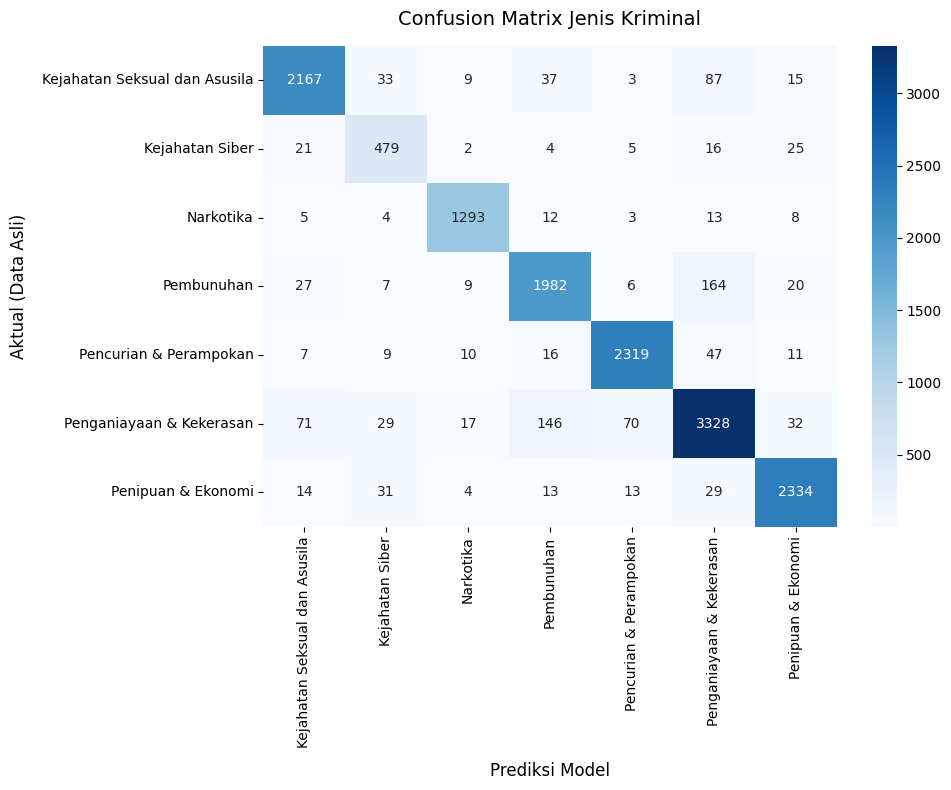


ANGKA CONFUSION MATRIX (7 KELAS):

Data Asli [Kejahatan Seksual dan Asusila] didistribusikan ke prediksi:
  -> Ditebak Kejahatan Seksual dan Asusila: 2167
  -> Ditebak Kejahatan Siber: 33
  -> Ditebak Narkotika: 9
  -> Ditebak Pembunuhan: 37
  -> Ditebak Pencurian & Perampokan: 3
  -> Ditebak Penganiayaan & Kekerasan: 87
  -> Ditebak Penipuan & Ekonomi: 15

Data Asli [Kejahatan Siber] didistribusikan ke prediksi:
  -> Ditebak Kejahatan Seksual dan Asusila: 21
  -> Ditebak Kejahatan Siber: 479
  -> Ditebak Narkotika: 2
  -> Ditebak Pembunuhan: 4
  -> Ditebak Pencurian & Perampokan: 5
  -> Ditebak Penganiayaan & Kekerasan: 16
  -> Ditebak Penipuan & Ekonomi: 25

Data Asli [Narkotika] didistribusikan ke prediksi:
  -> Ditebak Kejahatan Seksual dan Asusila: 5
  -> Ditebak Kejahatan Siber: 4
  -> Ditebak Narkotika: 1293
  -> Ditebak Pembunuhan: 12
  -> Ditebak Pencurian & Perampokan: 3
  -> Ditebak Penganiayaan & Kekerasan: 13
  -> Ditebak Penipuan & Ekonomi: 8

Data Asli [Pembunuhan] didi

In [14]:
print(classification_report(y_test, pred_test_gini, target_names=URUTAN_KELAS))

cm = confusion_matrix(y_test, pred_test_gini, labels=URUTAN_KELAS)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=URUTAN_KELAS,
    yticklabels=URUTAN_KELAS
)

plt.title('Confusion Matrix Jenis Kriminal', fontsize=14, pad=15)
plt.xlabel('Prediksi Model', fontsize=12, labelpad=10)
plt.ylabel('Aktual (Data Asli)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

print("\nANGKA CONFUSION MATRIX (7 KELAS):")
for i, kelas_asli in enumerate(URUTAN_KELAS):
    print(f"\nData Asli [{kelas_asli}] didistribusikan ke prediksi:")
    for j, kelas_pred in enumerate(URUTAN_KELAS):
        if cm[i][j] > 0: 
            print(f"  -> Ditebak {kelas_pred}: {cm[i][j]}")

In [15]:
df_hasil_bersih = df_clean_kelas.copy()
X_clean_tfidf = tfidf.transform(df_hasil_bersih['text_clean'])

prediksi_bersih = model_gini.predict(X_clean_tfidf)
df_hasil_bersih['prediksi_jenis_dt'] = prediksi_bersih

nama_file_final = "data_jeniskriminal_SMOTE.csv"
df_hasil_bersih.to_csv(nama_file_final, index=False)